# 02 Ringing and Room Modes

**Series:** Physics of the Integratron (Landers, California)
**Topic T2:** why sound keeps ringing in the dome, which notes it rings at, and how long it lasts.

Notebook 01 followed a single clap: it reflects off the dome and refocuses every 49 ms. This notebook follows what happens over the following seconds.

1. **The echo train.** A sound at the centre returns again and again, weaker each time.
2. **Echoes become resonances.** A regular echo train reinforces some notes and cancels others.
3. **Mode shapes.** The patterns of standing waves the dome can hold, including ones that cling to the wall.
4. **From separate notes to a continuum.** Low notes ring one at a time. Higher up, the resonances overlap.
5. **How long it rings.** Reverberation time, and what the wall and the people in the room do to it.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq
from scipy.special import lpmv, spherical_jn
from ipywidgets import interact, Dropdown, FloatSlider, IntSlider

SPEED_OF_SOUND = 343.0                   # m/s, air at 20 °C
DOME_RADIUS = 55 * 0.3048 / 2            # 55 ft diameter -> 8.38 m
R = DOME_RADIUS
ROOM_VOLUME = 2 / 3 * np.pi * R ** 3     # hemisphere above the floor
ROOM_SURFACE = 2 * np.pi * R ** 2 + np.pi * R ** 2  # dome + floor
ROUND_TRIP_S = 2 * R / SPEED_OF_SOUND

BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8a85"
SLIDER_STYLE = {"handle_color": BLUE}  # visible knob on white backgrounds
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e4e3df",
    "lines.linewidth": 2,
})

print(f"Room volume {ROOM_VOLUME:.0f} m³, surface {ROOM_SURFACE:.0f} m²")
print(f"Round trip centre -> wall -> centre: {ROUND_TRIP_S * 1000:.1f} ms")

Room volume 1233 m³, surface 662 m²
Round trip centre -> wall -> centre: 48.9 ms


## 1. The echo train at the centre

From notebook 01: a clap at the centre goes out to the wall, reflects as one shrinking sphere, and returns to the centre after $2R/c = 49$ ms. It passes through the centre and repeats.

Each time the sound hits the wall, the wall absorbs a fraction $\alpha$ of its energy, called the **absorption coefficient**. After $n$ round trips the energy left is

$$E_n = (1 - \alpha)^n$$

Hard varnished wood absorbs a few percent. Soft materials such as cushions absorb much more. The slider sets $\alpha$ for the dome wall. No measured value for the Integratron is used here. The default of 0.05 is a typical figure for a hard surface.

Each pass through the centre also **inverts** the pulse, a 180° phase flip that a wave picks up at a point focus. This is the full 3D version of the shape change seen in notebook 01's 2D simulation.

In [2]:
def echo_t60(alpha):
    # Time for the centre echo train to lose 60 dB
    return 60 / (-10 * np.log10(1 - alpha)) * ROUND_TRIP_S


@interact(
    alpha=FloatSlider(value=0.05, min=0.01, max=0.5, step=0.01,
                      description="wall α", continuous_update=False,
                      style=SLIDER_STYLE),
)
def show_echo_train(alpha):
    n = np.arange(400)
    times = n * ROUND_TRIP_S
    amplitude = (-np.sqrt(1 - alpha)) ** n
    level_db = 10 * np.log10((1 - alpha) ** n)
    t60 = echo_t60(alpha)

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7))
    shown = times <= 0.6
    colours = np.where(amplitude[shown] > 0, BLUE, ORANGE)
    ax1.vlines(times[shown] * 1000, 0, amplitude[shown], colors=colours, linewidth=2.5)
    ax1.scatter(times[shown] * 1000, amplitude[shown], c=colours, s=25, zorder=3)
    ax1.axhline(0, color=GREY, linewidth=1)
    ax1.set_xlim(-10, 610)
    ax1.set_ylim(-1.1, 1.1)
    ax1.set_xlabel("time (ms)")
    ax1.set_ylabel("pulse at the centre")
    ax1.set_title("First 0.6 s: one echo every 49 ms, flipping sign each pass "
                  "(blue up, orange down)", fontsize=10)

    ax2.step(times, level_db, where="post", color=BLUE)
    ax2.axhline(-60, color=ORANGE, linestyle="--", linewidth=1)
    ax2.axvline(t60, color=ORANGE, linestyle="--", linewidth=1)
    ax2.text(t60, -5, f"  60 dB down after {t60:.1f} s ({t60 / ROUND_TRIP_S:.0f} echoes)",
             color=ORANGE, va="top")
    ax2.set_xlim(0, max(1.3 * t60, 0.5))
    ax2.set_ylim(-75, 3)
    ax2.set_xlabel("time (s)")
    ax2.set_ylabel("echo energy (dB)")
    ax2.set_title("Each echo loses the same fraction, so the level falls in a straight line",
                  fontsize=10)
    plt.tight_layout()
    plt.show()

interactive(children=(FloatSlider(value=0.05, continuous_update=False, description='wall α', max=0.5, min=0.01…

**What the plots show** (default α = 0.05)

- **Top:** the first 0.6 s at the centre. Each stem is one returning pulse. They arrive exactly 49 ms apart and alternate up (blue) and down (orange) because each pass through the centre flips the pulse. Each echo loses 5% of its energy, so the stems shrink slowly. The twelfth echo, at 0.59 s, still has 0.74 of the clap's amplitude.
- **Bottom:** the energy of each echo in decibels, over a longer time. Every round trip removes the same 5%, which is the same 0.22 dB, so the tiny steps form a straight line. The line reaches −60 dB, the standard point at which a sound counts as gone, after 13.2 s and 269 echoes. This time is the **reverberation time** $T_{60}$.

Twenty echoes arrive each second. At that rate the ear stops hearing separate repeats and hears a fast flutter.

**Try this:**

- Raise α to 0.3, about what a wall covered in heavy fabric absorbs. The stems shrink visibly from one echo to the next and $T_{60}$ falls to 1.9 s (39 echoes).
- Lower α to 0.01, a very hard polished surface. $T_{60}$ grows past a minute.

## 2. Echoes become resonances

Now play a **steady note** at the centre instead of a clap. Every 49 ms another copy of the note returns. Whether these copies add up or cancel depends on the frequency.

- One round trip is $2R$ of path, plus the 180° flip at the centre.
- If $2R$ holds a whole number of wavelengths **plus a half**, the half-wavelength cancels the flip. Every returning copy arrives in step with the note being played and they pile up. The note is **reinforced**.
- Halfway between those frequencies, alternate copies cancel. The note is **suppressed**.

Adding the copies with amplitude loss $r = \sqrt{1 - \alpha}$ per round trip gives

$$H(f) = \sum_{n=0}^{\infty} \left(-r\, e^{\,i\,2\pi f \cdot 2R/c}\right)^n = \frac{1}{1 + r\, e^{\,i\,2\pi f \cdot 2R/c}}$$

The peaks repeat every $c/2R = 20.5$ Hz, the inverse of the 49 ms echo time. The top plot shows the loudness $|H|^2$ at the centre. The grey dashes mark the exact resonant frequencies of a rigid sphere, from the full wave equation.

The bottom plot shows each peak close up. A peak's width is set by how fast the echoes die. Its half-power width is $B \approx 2.2 / T_{60}$.

In [3]:
def bessel_derivative_zeros(l, x_max):
    # Zeros of j_l'(x) for 0 < x <= x_max: a rigid sphere resonates at k R = zero
    x = np.linspace(0.01, x_max, int(x_max * 200))
    y = spherical_jn(l, x, derivative=True)
    brackets = np.flatnonzero(np.sign(y[:-1]) != np.sign(y[1:]))
    return np.array([brentq(lambda t: spherical_jn(l, t, derivative=True), x[i], x[i + 1])
                     for i in brackets])


def to_hz(kr):
    return kr * SPEED_OF_SOUND / (2 * np.pi * R)


RADIAL_MODES_HZ = to_hz(bessel_derivative_zeros(0, 60))


@interact(
    alpha=FloatSlider(value=0.05, min=0.01, max=0.5, step=0.01,
                      description="wall α", continuous_update=False,
                      style=SLIDER_STYLE),
)
def show_centre_resonances(alpha):
    f = np.linspace(1, 250, 20000)
    r = np.sqrt(1 - alpha)
    response = np.abs(1 / (1 + r * np.exp(2j * np.pi * f * ROUND_TRIP_S))) ** 2
    response_db = 10 * np.log10(response)
    t60 = echo_t60(alpha)

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7))
    ax1.plot(f, response_db, color=BLUE, linewidth=1.5)
    for fm in RADIAL_MODES_HZ[RADIAL_MODES_HZ < 250]:
        ax1.axvline(fm, color=GREY, linestyle="--", linewidth=0.8)
    ax1.set_xlim(0, 250)
    ax1.set_xlabel("frequency (Hz)")
    ax1.set_ylabel("loudness at centre (dB)")
    ax1.set_title(f"A comb of resonances every {1 / ROUND_TRIP_S:.1f} Hz "
                  "(grey: exact sphere resonances)", fontsize=10)

    centre = (4 + 0.5) / ROUND_TRIP_S
    zoom = np.abs(f - centre) < 0.5 / ROUND_TRIP_S
    ax2.plot(f[zoom], response[zoom] / response[zoom].max(), color=BLUE)
    width = 2.2 / t60
    ax2.axvspan(centre - width / 2, centre + width / 2, color=ORANGE, alpha=0.15,
                label=f"B = 2.2 / T60 = {width:.2f} Hz")
    ax2.axhline(0.5, color=GREY, linestyle=":", linewidth=1)
    ax2.set_xlabel("frequency (Hz)")
    ax2.set_ylabel("loudness (peak = 1)")
    ax2.set_title(f"One resonance close up: the echoes last {t60:.1f} s, "
                  f"so the peak is {width:.2f} Hz wide", fontsize=10)
    ax2.legend(loc="upper right", fontsize=8)
    plt.tight_layout()
    plt.show()

interactive(children=(FloatSlider(value=0.05, continuous_update=False, description='wall α', max=0.5, min=0.01…

**What the plots show** (default α = 0.05)

- **Top:** loudness at the centre for a steady note from 0 to 250 Hz, relative to the note with no dome around it. Sharp peaks stand every 20.5 Hz at +32 dB, which is 1600 times the energy. Between them the dips sit at −6 dB, where alternate echoes cancel the note.
- **Grey dashes:** the exact resonances of a rigid sphere (29.3, 50.3, 71.0, 91.6 Hz and up). From 50 Hz upward they sit on the echo-model peaks. Below that the model fails. It puts a peak at 10.2 Hz where the sphere has none, and its next peak is at 30.7 Hz instead of 29.3 Hz. At 10 Hz the wavelength is 34 m, twice the width of the room, and a bouncing pulse is no longer a fair picture.
- **Bottom:** the peak at 92 Hz close up. It is only 0.17 Hz wide at half height, matching $B = 2.2/T_{60}$ for the 13.2 s echo train (orange band). Long ringing and a narrow peak are the same fact seen in time and in frequency.

**Try this:**

- Raise α to 0.3. The peaks drop to +16 dB and widen to 1.16 Hz, while the dips barely move.

The comb continues across the whole audible range, with a peak every 20.5 Hz. A voice or singing bowl at the centre gets strong reinforcement when its pitch sits on a peak and much less halfway between.

### Hear it

The echo train is a simple rule: every 49 ms, a copy of what was played returns, flipped and weakened by $r = \sqrt{1-\alpha}$. In terms of audio samples that is

$$y[n] = x[n] - r\, y[n - D]$$

where $D$ is the number of samples in 49 ms. This is exactly the sum $H(f)$ above. The cell plays three sounds through it:

- **click:** a single click at the centre, followed by its echo train.
- **noise:** 3 s of hiss. Every frequency is present, so the comb's peaks and dips shape it.
- **slow sweep:** a tone gliding from 410 to 450 Hz over 10 s. It passes two comb peaks, at 419.4 Hz and 439.9 Hz.

Each player is set to its own volume, so compare how each sounds rather than how loud.

In [4]:
from IPython.display import Audio, display
from scipy.signal import lfilter

AUDIO_RATE = 22050
ECHO_SAMPLES = round(ROUND_TRIP_S * AUDIO_RATE)


def centre_echoes(signal, alpha):
    # y[n] = x[n] - r y[n - D]: every 49 ms a flipped, weakened copy comes back
    feedback = np.zeros(ECHO_SAMPLES + 1)
    feedback[0], feedback[-1] = 1.0, np.sqrt(1 - alpha)
    return lfilter([1.0], feedback, signal)


def dry_sound(name):
    rng = np.random.default_rng(0)
    if name == "click":
        dry = np.zeros(4 * AUDIO_RATE)
        dry[0] = 1.0
        return dry, None
    if name == "noise":
        dry = np.concatenate([rng.normal(size=3 * AUDIO_RATE), np.zeros(3 * AUDIO_RATE)])
        return dry, None
    t = np.arange(12 * AUDIO_RATE) / AUDIO_RATE
    sweep_s = 10.0
    freq = np.where(t < sweep_s, 410 + 40 * t / sweep_s, 450.0)
    dry = np.sin(2 * np.pi * np.cumsum(freq) / AUDIO_RATE) * (t < sweep_s)
    return dry, freq


def level_db(signal, window_s=0.02):
    n = int(window_s * AUDIO_RATE)
    frames = signal[:len(signal) // n * n].reshape(-1, n)
    return 10 * np.log10(np.mean(frames ** 2, axis=1) + 1e-12)


@interact(
    sound=Dropdown(options=["click", "noise", "slow sweep"], value="slow sweep",
                   description="sound"),
    alpha=FloatSlider(value=0.1, min=0.01, max=0.5, step=0.01, description="wall α",
                      continuous_update=False, style=SLIDER_STYLE),
)
def hear_centre(sound, alpha):
    dry, freq = dry_sound(sound)
    wet = centre_echoes(dry, alpha)
    t_frames = (np.arange(len(level_db(wet))) + 0.5) * 0.02

    fig, ax = plt.subplots(figsize=(11, 4))
    wet_db = level_db(wet)
    ax.plot(t_frames, level_db(dry) - wet_db.max(), color=GREY, linewidth=1,
            label="dry")
    ax.plot(t_frames, wet_db - wet_db.max(), color=BLUE, linewidth=1.2,
            label="at the centre")
    if freq is not None:
        for n in range(19, 23):
            peak = (n + 0.5) / ROUND_TRIP_S
            if 410 <= peak <= 450:
                when = (peak - 410) / 40 * 10
                ax.axvline(when, color=ORANGE, linestyle="--", linewidth=1)
                ax.text(when, 1, f" {peak:.1f} Hz peak", color=ORANGE, va="bottom",
                        fontsize=8)
    ax.set_ylim(-60, 6)
    ax.set_xlabel("time (s)")
    ax.set_ylabel("level (dB, loudest = 0)")
    ax.set_title(f"{sound} through the centre echo train, α = {alpha:.2f}", fontsize=10)
    ax.legend(fontsize=8, loc="lower right")
    plt.tight_layout()
    plt.show()
    print("Dry:")
    display(Audio(dry, rate=AUDIO_RATE))
    print("At the centre:")
    display(Audio(wet, rate=AUDIO_RATE))

interactive(children=(Dropdown(description='sound', index=2, options=('click', 'noise', 'slow sweep'), value='…

**What the plots show** (default: slow sweep, α = 0.1)

- **Grey** is the dry tone at a steady level. **Blue** is the same tone heard at the centre.
- The level climbs as the tone approaches each comb peak and tops out about 19 dB above the dry tone at 2.7 s and 7.8 s. Each top comes about 0.3 s after the tone passes the peak frequency (orange lines), because a resonance takes time to build up.
- After each top the level wobbles, faster and faster. The dome is still ringing at the peak frequency while the tone has moved on, and the two **beat**. The beat rate equals the gap between the two frequencies, so it speeds up as the sweep moves away.
- Between the peaks the tone sits a few dB below the dry level, in a dip of the comb. When the tone stops at 10 s the ringing carries on and fades over the last 2 s.

**Try this:**

- **click:** one click every 49 ms, each 0.46 dB weaker than the last, falling in a straight line to −37 dB after 4 s.
- **noise:** the hiss builds up over half a second to 10 dB above the dry level as returning copies pile up. That 10 dB is the gain averaged over all frequencies, $1/(1 - r^2)$. After the noise stops, the echoes carry it on and fade at 9.4 dB per second.
- **slow sweep, α = 0.02:** each peak is now only 0.07 Hz wide. The tone crosses it in under 20 ms, far too fast for the resonance to build fully. The ringing also lasts so long that the level never falls back between the peaks: the first resonance is still sounding when the second arrives.
- **slow sweep, α = 0.4:** the swells are broad and smooth, about 12 dB above the dry tone, and the beats die out within a second. When the tone stops, the sound is gone within about a second.

## 3. Mode shapes: the standing waves the dome can hold

The resonances in section 2 are only the ones that are loud at the centre. The dome has many more. Each resonance is a **mode**: a pattern of pressure that oscillates in place, loud at its **antinodes** and silent along its **nodes**.

For a hard sphere the modes are known exactly. The pressure is

$$p(r, \theta, \phi) = j_l(k r)\; P_l^m(\cos\theta)\; \cos(m\phi)$$

- $j_l$ is a **spherical Bessel function**. It sets how pressure varies with distance from the centre.
- $P_l^m$ is a **Legendre function**. It sets how pressure varies from the top of the dome ($\theta = 0$) down to the floor ($\theta = 90°$).
- $\cos(m\phi)$ sets how pressure varies around the room, seen from above.
- The hard wall requires zero pressure gradient across it, so $k R$ must be a zero of $j_l'$. The $n$-th zero gives the $n$-th mode for that $l$, at frequency $f = k c / 2\pi$.

The floor adds one rule. The real room is half of the sphere, and the hard floor mirrors it, so only modes that are symmetric about the floor exist. That keeps modes with $l + m$ even and removes the rest. The others have zero pressure on the floor and air flowing straight through it, which a hard floor blocks.

Each panel shows a vertical slice through the centre, like the plots in notebook 01. Red and blue are opposite pressures half a cycle apart. White is a node.

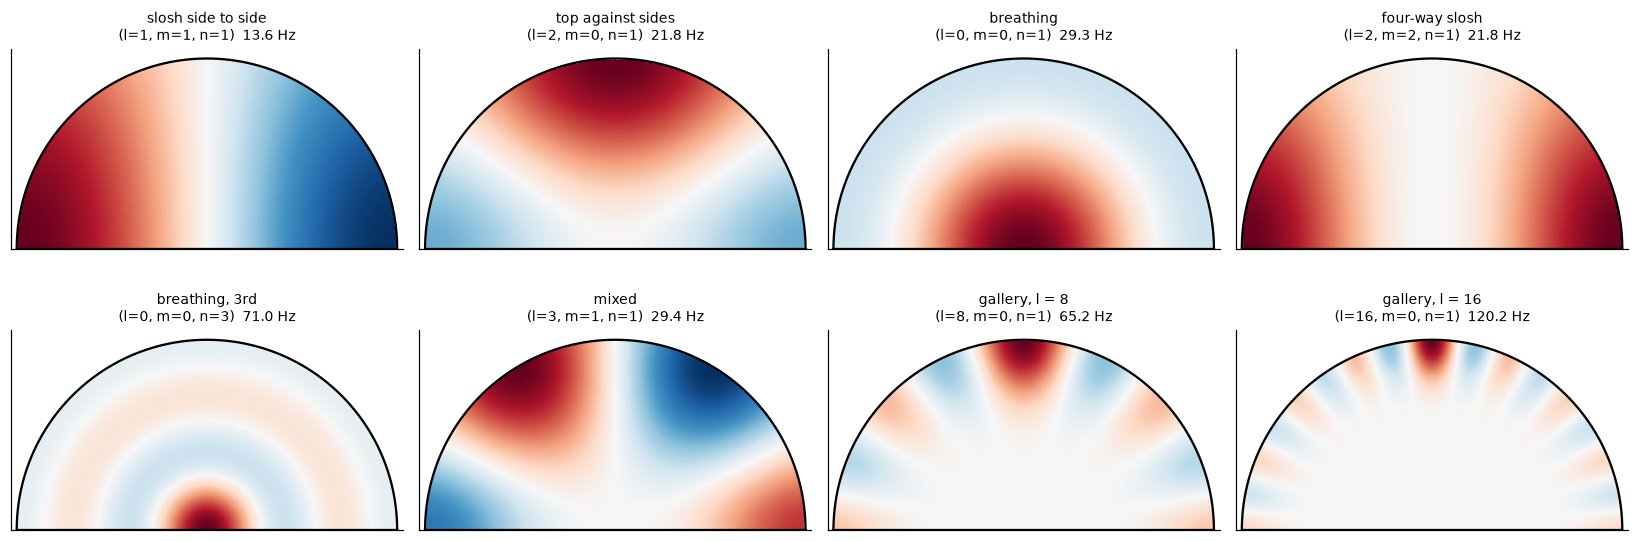

In [5]:
def mode_frequency(l, n):
    return to_hz(bessel_derivative_zeros(l, 40 + 2 * l)[n - 1])


def mode_pressure(l, m, n, x, y, z):
    # Pressure of mode (l, m, n) at points x, y, z (z up, floor at z = 0)
    k = bessel_derivative_zeros(l, 40 + 2 * l)[n - 1] / R
    r = np.sqrt(x ** 2 + y ** 2 + z ** 2)
    cos_theta = np.divide(z, r, out=np.ones_like(r), where=r > 0)
    phi = np.arctan2(y, x)
    return spherical_jn(l, k * r) * lpmv(m, l, cos_theta) * np.cos(m * phi)


SLICE_X, SLICE_Z = np.meshgrid(np.linspace(-R, R, 301), np.linspace(0, R, 151))
SLICE_INSIDE = SLICE_X ** 2 + SLICE_Z ** 2 <= R ** 2


def draw_slice(ax, l, m, n):
    p = mode_pressure(l, m, n, SLICE_X, np.zeros_like(SLICE_X), SLICE_Z)
    p = np.where(SLICE_INSIDE, p, np.nan)
    p /= np.nanmax(np.abs(p))
    ax.imshow(p, origin="lower", extent=[-R, R, 0, R], cmap="RdBu_r", vmin=-1, vmax=1)
    phi = np.linspace(0, np.pi, 200)
    ax.plot(R * np.cos(phi), R * np.sin(phi), color="k", linewidth=1.5)
    ax.plot([-R, R], [0, 0], color="k", linewidth=1.5)
    ax.set_aspect("equal")
    ax.set_xlim(-R * 1.03, R * 1.03)
    ax.set_ylim(0, R * 1.05)
    ax.grid(False)
    ax.set_xticks([])
    ax.set_yticks([])


GALLERY = [
    (1, 1, 1, "slosh side to side"),
    (2, 0, 1, "top against sides"),
    (0, 0, 1, "breathing"),
    (2, 2, 1, "four-way slosh"),
    (0, 0, 3, "breathing, 3rd"),
    (3, 1, 1, "mixed"),
    (8, 0, 1, "gallery, l = 8"),
    (16, 0, 1, "gallery, l = 16"),
]

fig, axes = plt.subplots(2, 4, figsize=(15, 5.6))
for ax, (l, m, n, label) in zip(axes.flat, GALLERY):
    draw_slice(ax, l, m, n)
    ax.set_title(f"{label}\n(l={l}, m={m}, n={n})  {mode_frequency(l, n):.1f} Hz",
                 fontsize=9)
plt.tight_layout()
plt.show()

**What the figure shows**

Eight modes in the vertical slice, with the floor along the bottom edge. Each panel uses its own colour scale.

- **Slosh side to side, 13.6 Hz:** the lowest mode. Pressure is high on one side while it is low on the other, and they swap every half cycle, so air rushes back and forth across the room. 13.6 Hz is below the range of hearing. It can be felt rather than heard.
- **Top against sides, 21.8 Hz:** the top of the dome is high while the edges near the floor are low.
- **Breathing, 29.3 Hz:** pressure rises and falls everywhere together, strongest at the centre. This is the first of the centre resonances from section 2.
- **Four-way slosh, 21.8 Hz:** in this slice both sides are in step. From above it has four lobes (try $l = 2$, $m = 2$ in the explorer). It has exactly the same frequency as "top against sides". In a sphere every mode with the same $l$ and $n$ shares one frequency, however it is turned.
- **Breathing, 3rd, 71.0 Hz:** three rings with the strongest at the centre. A 71 Hz note sung at the centre drives this mode.
- **Mixed, 29.4 Hz:** a pattern that changes both with height and from side to side.
- **Gallery, l = 8 (65.2 Hz) and l = 16 (120.2 Hz):** lobes pressed into a band against the dome, with silence in the middle. These are **whispering gallery modes**. The sound runs along the curved wall, held there by repeated grazing reflections, and never crosses the room. The higher $l$ is, the thinner the band.

### Mode explorer

Pick any mode. The left panel is the vertical slice. The right panel is the floor seen from above, where the people lie. Modes with $l + m$ odd do not exist in the dome and are marked as missing. The slider for $m$ is capped at $l$.

In [6]:
FLOOR_X, FLOOR_Y = np.meshgrid(np.linspace(-R, R, 241), np.linspace(-R, R, 241))
FLOOR_INSIDE = FLOOR_X ** 2 + FLOOR_Y ** 2 <= R ** 2


@interact(
    l=IntSlider(value=16, min=0, max=24, description="l", continuous_update=False,
                style=SLIDER_STYLE),
    m=IntSlider(value=16, min=0, max=24, description="m", continuous_update=False,
                style=SLIDER_STYLE),
    n=IntSlider(value=1, min=1, max=4, description="n", continuous_update=False,
                style=SLIDER_STYLE),
)
def show_mode(l, m, n):
    m = min(m, l)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8),
                                   gridspec_kw={"width_ratios": [1.6, 1]})
    title = f"Mode l={l}, m={m}, n={n}: {mode_frequency(l, n):.1f} Hz"
    if (l + m) % 2:
        for ax in (ax1, ax2):
            ax.axis("off")
        fig.text(0.5, 0.5, f"{title}\nl + m is odd: this mode has zero pressure on the "
                 "floor and air flowing straight through it.\nThe hard floor blocks "
                 "that flow, so the mode is missing from the dome.",
                 ha="center", va="center", fontsize=11)
        plt.show()
        return

    draw_slice(ax1, l, m, n)
    ax1.set_title("Vertical slice through the centre", fontsize=10)

    p = mode_pressure(l, m, n, FLOOR_X, FLOOR_Y, np.zeros_like(FLOOR_X))
    p = np.where(FLOOR_INSIDE, p, np.nan)
    p /= np.nanmax(np.abs(p))
    ax2.imshow(p, origin="lower", extent=[-R, R, -R, R], cmap="RdBu_r", vmin=-1, vmax=1)
    phi = np.linspace(0, 2 * np.pi, 300)
    ax2.plot(R * np.cos(phi), R * np.sin(phi), color="k", linewidth=1.5)
    ax2.set_aspect("equal")
    ax2.grid(False)
    ax2.set_xticks([])
    ax2.set_yticks([])
    ax2.set_title("The floor from above", fontsize=10)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

interactive(children=(IntSlider(value=16, continuous_update=False, description='l', max=24, style=SliderStyle(…

**What the plots show** (default l = 16, m = 16, n = 1, 120.2 Hz)

- **Left:** in the vertical slice there is pressure only in two small patches where the dome meets the floor. The rest of the room is silent.
- **Right:** from above, a ring of 32 lobes (16 red, 16 blue) runs around the wall at floor level, with a silent centre. This is a whispering gallery mode that runs horizontally around the room, close to people lying near the wall.

**Try this:**

- Set $m = 0$ with $l = 16$. The gallery now runs up and over the top of the dome, as in the gallery figure. From above it becomes a single ring around the edge.
- Set $l = 3$, $m = 2$. This mode is missing because $l + m$ is odd.
- Set $l = 4$, $m = 2$, $n = 2$ (64.1 Hz). From above there are two red and two blue lobes. In the slice there is a second layer of lobes inside the first. Each step up in $n$ adds a layer between the centre and the wall.
- Set $l = 0$ and step through $n$. These are the breathing modes. From above they are rings.

## 4. From separate notes to a continuum

Every mode rings like a bell at its own frequency, and every mode decays. A mode that rings for $T_{60}$ seconds responds to a band of frequencies $B \approx 2.2 / T_{60}$ wide around its own frequency.

- When modes are **further apart** than their width, the room has distinct resonant notes. A note that matches a mode booms. A note between modes is weak.
- When modes are **closer together** than their width, they overlap. Every note excites several modes and the response evens out.

The number of modes grows with the cube of frequency, so there is always a crossover. It is called the **Schroeder frequency**:

$$f_S \approx 2000 \sqrt{\frac{T_{60}}{V}}$$

with $T_{60}$ in seconds and the room volume $V$ in m³.

The plots compute every mode of the dome up to 250 Hz.

- **Top:** each mode drawn as a resonance peak with the width set by the slider's $T_{60}$, summed. Below $f_S$ the peaks stand apart. Above it they merge.
- **Bottom:** the number of modes below each frequency, against the standard estimate $N \approx \frac{4\pi V}{3}\left(\frac{f}{c}\right)^3 + \frac{\pi S}{4}\left(\frac{f}{c}\right)^2$.

In [7]:
def all_modes(f_max):
    # Every allowed mode of the hemisphere below f_max: (frequency, l, m, copies).
    # m > 0 has two copies, cos(m phi) and sin(m phi).
    x_max = 2 * np.pi * f_max * R / SPEED_OF_SOUND
    modes = []
    for l in range(int(x_max) + 2):
        for kr in bessel_derivative_zeros(l, x_max):
            for m in range(l + 1):
                if (l + m) % 2 == 0:
                    modes.append((to_hz(kr), l, m, 1 if m == 0 else 2))
    return np.array(sorted(modes))


MODES = all_modes(250)
print(f"{int(MODES[:, 3].sum())} modes below 250 Hz")


@interact(
    t60=FloatSlider(value=6.0, min=0.5, max=10.0, step=0.5, description="T60 (s)",
                    continuous_update=False, style=SLIDER_STYLE),
)
def show_mode_overlap(t60):
    f = np.linspace(5, 250, 12000)
    width = 2.2 / t60
    response = np.zeros_like(f)
    for fm, _, _, copies in MODES:
        response += copies / (1 + ((f - fm) / (width / 2)) ** 2)
    schroeder = 2000 * np.sqrt(t60 / ROOM_VOLUME)

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
    ax1.plot(f, response, color=BLUE, linewidth=1)
    ax1.axvline(schroeder, color=ORANGE, linestyle="--", linewidth=1.2)
    ax1.text(schroeder, ax1.get_ylim()[1] * 0.92, f"  Schroeder {schroeder:.0f} Hz",
             color=ORANGE, va="top")
    ax1.set_ylabel("summed mode response")
    ax1.set_title(f"Every mode as a peak {width:.2f} Hz wide (T60 = {t60} s)",
                  fontsize=10)

    counts = np.cumsum(MODES[:, 3])
    ax2.step(MODES[:, 0], counts, where="post", color=BLUE, label="counted modes")
    estimate = (4 * np.pi * ROOM_VOLUME / 3 * (f / SPEED_OF_SOUND) ** 3
                + np.pi * ROOM_SURFACE / 4 * (f / SPEED_OF_SOUND) ** 2)
    ax2.plot(f, estimate, color=GREY, linestyle="--", label="estimate")
    ax2.axvline(schroeder, color=ORANGE, linestyle="--", linewidth=1.2)
    ax2.set_xlabel("frequency (Hz)")
    ax2.set_ylabel("modes below f")
    ax2.set_xlim(0, 250)
    ax2.legend(loc="upper left")
    plt.tight_layout()
    plt.show()

2296 modes below 250 Hz


interactive(children=(FloatSlider(value=6.0, continuous_update=False, description='T60 (s)', max=10.0, min=0.5…

**What the plots show** (default $T_{60}$ = 6 s, the value section 5 gives for an empty dome with α = 0.05)

- **Top:** each mode is a peak 0.37 Hz wide. Below about 80 Hz they stand alone, with near silence between them. A note there either matches a mode and booms or misses and stays weak. Toward the Schroeder line at 139 Hz the gaps fill in. Above it the response is continuous but still spiky, with single peaks several times taller than their neighbours.
- **Bottom:** the count of modes climbs from a handful below 50 Hz to 2296 below 250 Hz. The count and the estimate lie on top of each other, which checks the mode calculation.

The tall spikes above the Schroeder frequency are where the sphere differs from an ordinary room. In a box-shaped room the modes are scattered at random frequencies. In a sphere every mode with the same $l$ and $n$ has the same frequency. For $l = 30$ that stacks 31 modes on one note. The Schroeder rule assumes the scattered case, so the dome keeps distinct resonant notes well above $f_S$.

**Try this:**

- Lower $T_{60}$ to 1 s. Each mode is 2.2 Hz wide, the Schroeder line moves to 57 Hz, and the top curve becomes smooth bumps. Short ringing blurs the notes together.
- Raise it to 10 s. The peaks become needles and the dome sounds like a set of tuned resonators.

## 5. How long it rings

The usual way to estimate ringing is **Sabine's formula**. It assumes sound is scattered evenly through the room and hits every surface equally often:

$$T_{60} = 0.161 \, \frac{V}{A}, \qquad A = \alpha S + A_\text{people}$$

$A$ is the total **absorption** in m², the area of a perfect absorber that would soak up the same energy. For the dome, $V = 1232$ m³ and $S = 662$ m² (dome plus floor).

People absorb sound too. A common figure for a seated adult at mid frequencies is about 0.45 m² each. The model uses that for people lying on the floor, which is an assumption.

The smooth dome breaks Sabine's assumption. Sound that starts at the centre never scatters. It travels the full $2R$ between wall hits and never hits the floor, while scattered sound hits a surface every $4V/S = 7.4$ m on average. So the centre's echo train fades more slowly than the room as a whole, and the people lying on the floor do not absorb it. The plot shows both.

In [8]:
ABSORPTION_PER_PERSON = 0.45  # m², assumed


def sabine_t60(alpha, people):
    return 0.161 * ROOM_VOLUME / (alpha * ROOM_SURFACE + people * ABSORPTION_PER_PERSON)


@interact(
    alpha=FloatSlider(value=0.05, min=0.01, max=0.5, step=0.01, description="wall α",
                      continuous_update=False, style=SLIDER_STYLE),
    people=IntSlider(value=0, min=0, max=60, step=5, description="people",
                     continuous_update=False, style=SLIDER_STYLE),
)
def show_ringing(alpha, people):
    t_room = sabine_t60(alpha, people)
    t_centre = echo_t60(alpha)
    t = np.linspace(0, 1.2 * max(t_room, t_centre), 600)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.6))
    ax1.plot(t, -60 * t / t_room, color=BLUE, label=f"room (Sabine): T60 = {t_room:.1f} s")
    n = np.arange(int(t[-1] / ROUND_TRIP_S) + 1)
    ax1.step(n * ROUND_TRIP_S, 10 * np.log10((1 - alpha) ** n), where="post", color=AQUA,
             label=f"centre echo train: T60 = {t_centre:.1f} s")
    ax1.axhline(-60, color=ORANGE, linestyle="--", linewidth=1)
    ax1.set_ylim(-75, 3)
    ax1.set_xlim(0, t[-1])
    ax1.set_xlabel("time after the sound stops (s)")
    ax1.set_ylabel("level (dB)")
    ax1.set_title("How fast the sound dies away", fontsize=10)
    ax1.legend(fontsize=8)

    alphas = np.linspace(0.01, 0.5, 200)
    for crowd, colour in zip([0, 20, 60], [BLUE, GREY, ORANGE]):
        ax2.plot(alphas, sabine_t60(alphas, crowd), color=colour,
                 label=f"{crowd} people")
    ax2.plot(alphas, echo_t60(alphas), color=AQUA, linestyle="--",
             label="centre echo train")
    ax2.scatter([alpha], [t_room], s=80, color=BLUE, zorder=4)
    ax2.set_yscale("log")
    ax2.set_xlabel("wall absorption α")
    ax2.set_ylabel("T60 (s)")
    ax2.set_title("Reverberation time vs wall absorption", fontsize=10)
    ax2.legend(fontsize=8)
    plt.tight_layout()
    plt.show()

interactive(children=(FloatSlider(value=0.05, continuous_update=False, description='wall α', max=0.5, min=0.01…

**What the plots show** (default α = 0.05, no people)

- **Left:** the blue line is Sabine's estimate for the room as a whole. It reaches −60 dB after 6.0 s. The green staircase is the echo train from section 1, which takes 13.2 s. Sound launched from the centre rings more than twice as long as the room's average, because it hits the wall only once every 16.8 m of travel.
- **Right:** $T_{60}$ against wall absorption on a log scale. The blue dot is the current setting. All curves fall steeply: going from α = 0.01 to 0.1 cuts the empty room's $T_{60}$ from 30 s to 3 s. People matter most when the wall is hard. At α = 0.01, sixty people (orange) cut $T_{60}$ from 30 s to 6 s. Above α = 0.3 the wall dominates and people make little difference. The green dashed curve is about 2.2 times the empty-room curve at every α.

**Try this:**

- Set people to 30. The room's $T_{60}$ drops from 6.0 s to 4.3 s. The centre echo train stays at 13.2 s, because sound that runs straight through the centre never touches the floor where people lie.
- Set α to 0.2 with 30 people. The room rings for 1.4 s and the centre for 3.0 s.

## Summary

| Idea | Formula | Integratron scale |
|---|---|---|
| Echo period at the centre | $2R/c$ | 49 ms, 20.5 echoes per second |
| Echo decay | $E_n = (1-\alpha)^n$ | $T_{60}$ = 13 s at α = 0.05 |
| Resonance spacing at the centre | $c/2R$ | 20.5 Hz |
| Resonance width | $B \approx 2.2/T_{60}$ | 0.17 Hz for a 13 s echo train |
| Mode shapes | $j_l(kr)\,P_l^m(\cos\theta)\cos m\phi$, $l+m$ even | lowest 13.6 Hz, 2296 below 250 Hz |
| Schroeder frequency | $2000\sqrt{T_{60}/V}$ | 139 Hz at $T_{60}$ = 6 s |
| Room reverberation (Sabine) | $0.161\,V/A$ | 6 s at α = 0.05, empty |

1. A sound at the centre returns every 49 ms, flipped each time, losing the fraction α of its energy at each wall hit.
2. A regular echo train is the same thing as a comb of resonances 20.5 Hz apart. Long ringing and sharp resonances are one fact seen two ways.
3. The dome's standing waves include breathing modes centred on the middle and whispering gallery modes that cling to the wall. The hard floor removes the modes with $l + m$ odd.
4. Below the Schroeder frequency the dome has separate resonant notes. Above it the modes overlap, but the sphere stacks many modes on the same frequency, so the response stays uneven.
5. Sabine's formula gives the room's average ringing. Sound launched from the centre rings about twice as long, and people lying on the floor do not shorten it.

**Next:** [03 Focusing in 3D](03_3d_focusing.ipynb): the focusing from notebook 01 computed over the whole dome instead of a slice.